<a href="https://colab.research.google.com/github/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/blob/main/Week_11/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Raw GitHub URLs for both Excel files
url_emisi = 'https://github.com/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/raw/main/Week_11/emisiCO2.xlsx'
url_karhutla = 'https://github.com/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/raw/main/Week_11/luas-karhutla-provinsi.xlsx?raw=true'

# Load both Excel files into DataFrames
df_emisi = pd.read_excel(url_emisi)
df_karhutla = pd.read_excel(url_karhutla)

# Display the first few rows of both dataframes
print("=== Data Emisi CO2 ===")
display(df_emisi.head())

print("\n=== Data Luas Karhutla Provinsi ===")
display(df_karhutla.head())

=== Data Emisi CO2 ===


,Provinsi,2023
0,Aceh,"385.417,00"
1,Bali,"95.214,00"
2,Bangka Belitung,"727.226,00"
3,Banten,"228,00"
4,Bengkulu,"13.372,00"



=== Data Luas Karhutla Provinsi ===


,Kode Wilayah,Provinsi,2023
0,11.0,Aceh,"1.936,86"
1,51.0,Bali,"2.011,27"
2,19.0,Bangka Belitung,"4.752,98"
3,36.0,Banten,"1,01"
4,17.0,Bengkulu,"75,94"


### 1. Data Cleaning, Merging & Feature Engineering

In [2]:
import numpy as np

# Clone data asli agar aman
df_emisi_clean = df_emisi.copy()
df_karhutla_clean = df_karhutla.copy()

# Pembersihan kolom: Hapus spasi pada nama kolom jika ada
df_emisi_clean.columns = df_emisi_clean.columns.str.strip()
df_karhutla_clean.columns = df_karhutla_clean.columns.str.strip()

# Hapus baris 'Total' dari masing-masing DataFrame
df_emisi_clean = df_emisi_clean[df_emisi_clean['Provinsi'].str.lower() != 'total']
df_karhutla_clean = df_karhutla_clean[df_karhutla_clean['Provinsi'].str.lower() != 'total']

# Bersihkan format angka string (mengubah titik ribuan menjadi numeric, koma desimal menjadi titik desimal)
def clean_numeric(val):
    if isinstance(val, str):
        val = val.replace('.', '').replace(',', '.')
    return float(val)

df_emisi_clean['2023'] = df_emisi_clean['2023'].apply(clean_numeric)
df_karhutla_clean['2023'] = df_karhutla_clean['2023'].apply(clean_numeric)

# Ganti nama kolom nilai untuk persiapan merging
df_emisi_clean = df_emisi_clean.rename(columns={'2023': 'emisi_co2'})
df_karhutla_clean = df_karhutla_clean.rename(columns={'2023': 'luas_karhutla'})

# Merge dataset berdasarkan Provinsi
df_merged = pd.merge(
    df_emisi_clean[['Provinsi', 'emisi_co2']],
    df_karhutla_clean[['Provinsi', 'luas_karhutla']],
    on='Provinsi',
    how='inner'
)

# Sesuai instruksi: Keluarkan DKI Jakarta karena nilainya 0 / tidak ada kebakaran
df_merged = df_merged[df_merged['Provinsi'].str.lower() != 'dki jakarta']

# Feature Engineering: Emisi per Hektar (emisi_co2 / luas_karhutla)
# Hindari pembagian dengan nol jika luas_karhutla = 0
df_merged['emisi_per_ha'] = df_merged.apply(
    lambda r: r['emisi_co2'] / r['luas_karhutla'] if r['luas_karhutla'] > 0 else 0.0, axis=1
)

print(f"Jumlah provinsi setelah DKI Jakarta dikeluarkan: {len(df_merged)}")
display(df_merged.head(10))

Jumlah provinsi setelah DKI Jakarta dikeluarkan: 37


,Provinsi,emisi_co2,luas_karhutla,emisi_per_ha
0,Aceh,385417.0,1936.86,198.990634
1,Bali,95214.0,2011.27,47.340238
2,Bangka Belitung,727226.0,4752.98,153.004221
3,Banten,228.0,1.01,225.742574
4,Bengkulu,13372.0,75.94,176.086384
6,Gorontalo,46344.0,666.33,69.551123
7,Jambi,1082497.0,6539.68,165.527518
8,Jawa Barat,626097.0,11524.80,54.326062
9,Jawa Tengah,1193013.0,9965.59,119.713233
10,Jawa Timur,7489228.0,49498.32,151.302670


### 2. Exploratory Data Analysis & Standardisasi Fitur

=== Matriks Korelasi ===


,emisi_co2,luas_karhutla,emisi_per_ha
emisi_co2,1.000000,0.814344,0.351051
luas_karhutla,0.814344,1.000000,0.070787
emisi_per_ha,0.351051,0.070787,1.000000


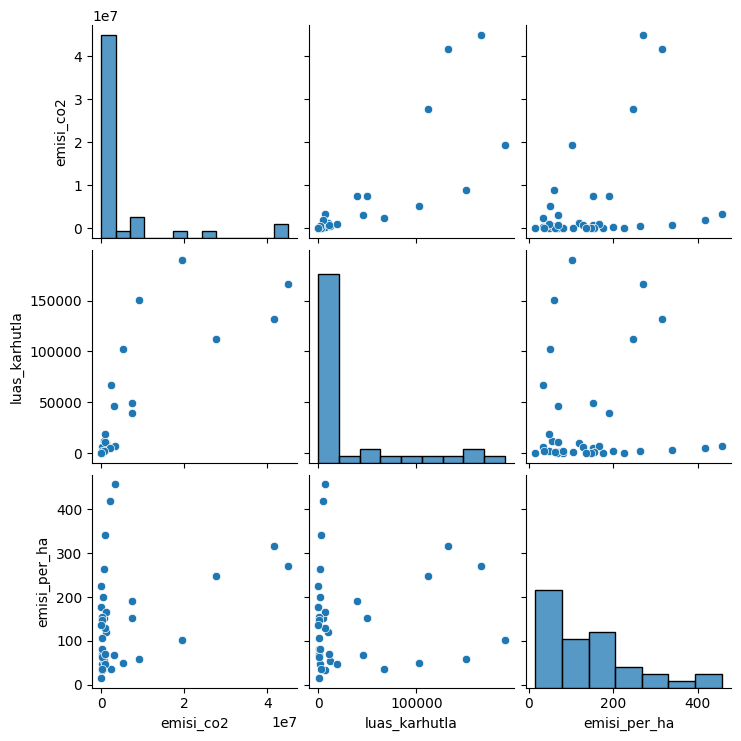

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Tampilkan korelasi antar fitur
print("=== Matriks Korelasi ===")
display(df_merged[['emisi_co2', 'luas_karhutla', 'emisi_per_ha']].corr())

# Visualisasi korelasi dan distribusi
sns.pairplot(df_merged[['emisi_co2', 'luas_karhutla', 'emisi_per_ha']])
plt.show()

# Standardisasi fitur untuk Skenario 1 (hanya emisi) dan Skenario 2 (luas + emisi_per_ha)
scaler_sc1 = StandardScaler()
X_sc1 = scaler_sc1.fit_transform(df_merged[['emisi_co2']])

scaler_sc2 = StandardScaler()
X_sc2 = scaler_sc2.fit_transform(df_merged[['luas_karhutla', 'emisi_per_ha']])

### 3. Penentuan Jumlah Klaster Optimal (Elbow & Silhouette Method)
Kita akan mengevaluasi klaster optimal (K) untuk kedua skenario menggunakan K-Means terlebih dahulu.

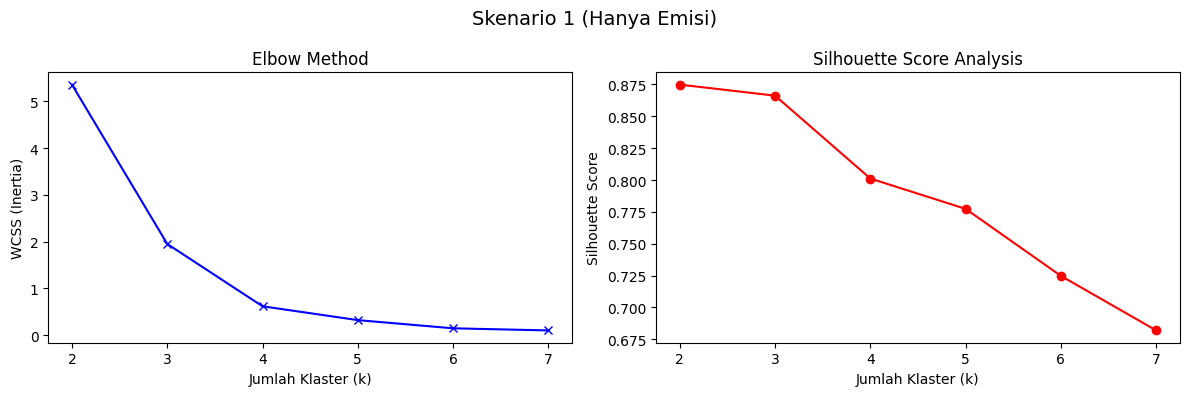

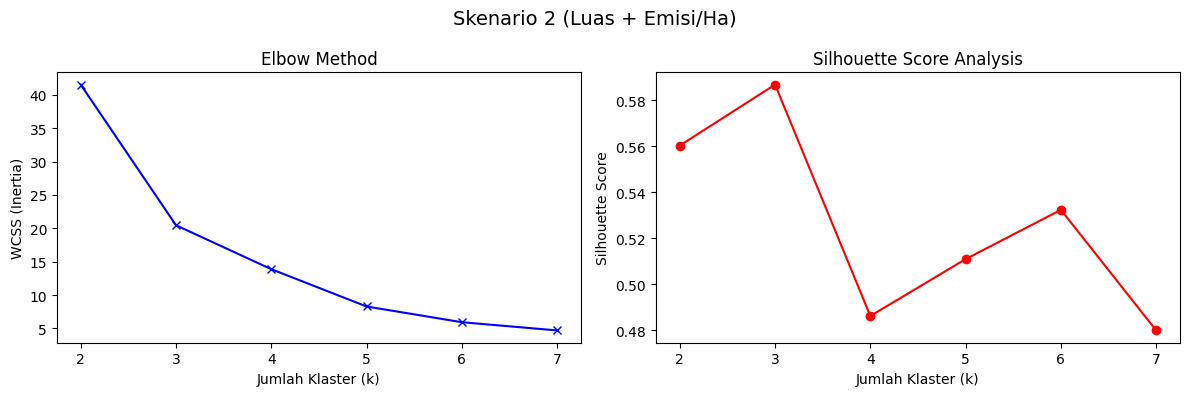

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# List untuk menampung metrik evaluasi
for label, X in [("Skenario 1 (Hanya Emisi)", X_sc1), ("Skenario 2 (Luas + Emisi/Ha)", X_sc2)]:
    wcss = []
    sil_scores = []
    k_range = range(2, 8)

    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        wcss.append(kmeans.inertia_)
        sil_scores.append(silhouette_score(X, kmeans.labels_))

    # Plotting
    fig, ax1 = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(label, fontsize=14)

    ax1[0].plot(k_range, wcss, 'bx-')
    ax1[0].set_xlabel('Jumlah Klaster (k)')
    ax1[0].set_ylabel('WCSS (Inertia)')
    ax1[0].set_title('Elbow Method')

    ax1[1].plot(k_range, sil_scores, 'ro-')
    ax1[1].set_xlabel('Jumlah Klaster (k)')
    ax1[1].set_ylabel('Silhouette Score')
    ax1[1].set_title('Silhouette Score Analysis')

    plt.tight_layout()
    plt.show()

### 4. Perbandingan Algoritma (K-Means, Hierarchical, GMM) untuk Kedua Skenario
Berdasarkan hasil analisis Elbow & Silhouette di atas, kita akan mengasumsikan jumlah klaster optimal yang umum digunakan (misalnya **k = 3**).

In [5]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture

n_clusters = 3

# --- SKENARIO 1 (Hanya Emisi) ---
kmeans_sc1 = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit(X_sc1)
hier_sc1 = AgglomerativeClustering(n_clusters=n_clusters).fit(X_sc1)
gmm_sc1 = GaussianMixture(n_components=n_clusters, random_state=42).fit(X_sc1)

df_sc1 = df_merged.copy()
df_sc1['KMeans_Cluster'] = kmeans_sc1.labels_
df_sc1['Hierarchical_Cluster'] = hier_sc1.labels_
df_sc1['GMM_Cluster'] = gmm_sc1.predict(X_sc1)

# --- SKENARIO 2 (Luas + Emisi per Ha) ---
kmeans_sc2 = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit(X_sc2)
hier_sc2 = AgglomerativeClustering(n_clusters=n_clusters).fit(X_sc2)
gmm_sc2 = GaussianMixture(n_components=n_clusters, random_state=42).fit(X_sc2)

df_sc2 = df_merged.copy()
df_sc2['KMeans_Cluster'] = kmeans_sc2.labels_
df_sc2['Hierarchical_Cluster'] = hier_sc2.labels_
df_sc2['GMM_Cluster'] = gmm_sc2.predict(X_sc2)

# Tampilkan sampel klasterisasi K-Means Skenario 2
print("=== Sampel Hasil Klasterisasi K-Means Skenario 2 ===")
display(df_sc2[['Provinsi', 'emisi_co2', 'luas_karhutla', 'emisi_per_ha', 'KMeans_Cluster']].head(10))

=== Sampel Hasil Klasterisasi K-Means Skenario 2 ===


,Provinsi,emisi_co2,luas_karhutla,emisi_per_ha,KMeans_Cluster
0,Aceh,385417.0,1936.86,198.990634,0
1,Bali,95214.0,2011.27,47.340238,0
2,Bangka Belitung,727226.0,4752.98,153.004221,0
3,Banten,228.0,1.01,225.742574,0
4,Bengkulu,13372.0,75.94,176.086384,0
6,Gorontalo,46344.0,666.33,69.551123,0
7,Jambi,1082497.0,6539.68,165.527518,0
8,Jawa Barat,626097.0,11524.80,54.326062,0
9,Jawa Tengah,1193013.0,9965.59,119.713233,0
10,Jawa Timur,7489228.0,49498.32,151.302670,0


### 5. Profiling Klaster & Visualisasi Distribusi
Mari kita bandingkan karakteristik masing-masing klaster pada Skenario 2 menggunakan model K-Means.

=== Profil Rata-Rata Tiap Klaster (Skenario 2 - KMeans) ===


,KMeans_Cluster,emisi_co2,luas_karhutla,emisi_per_ha
0,0,1.038508e+06,10768.908889,104.547888
1,1,2.464497e+07,142262.090000,174.321141
2,2,1.701228e+06,4214.955000,369.944858


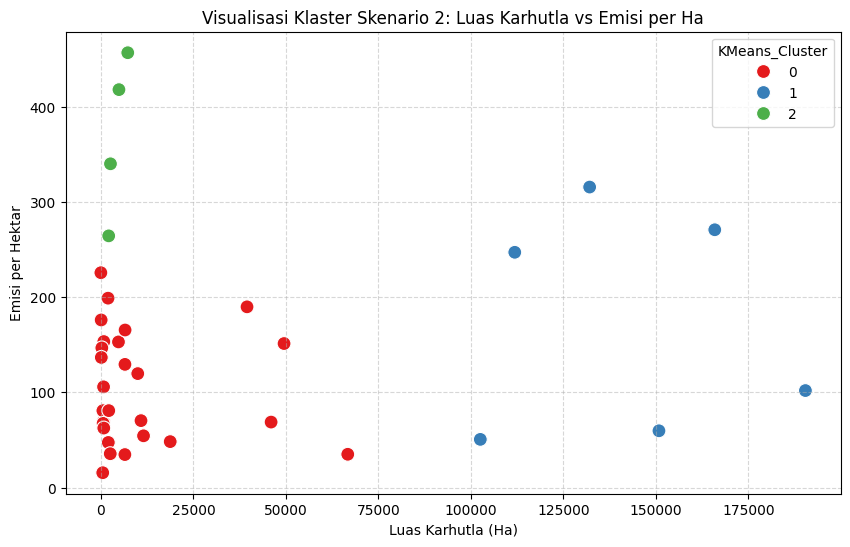

In [6]:
# Profil rata-rata klaster pada Skenario 2 (K-Means)
profil_sc2 = df_sc2.groupby('KMeans_Cluster')[['emisi_co2', 'luas_karhutla', 'emisi_per_ha']].mean().reset_index()
print("=== Profil Rata-Rata Tiap Klaster (Skenario 2 - KMeans) ===")
display(profil_sc2)

# Visualisasi Plot Klaster Skenario 2
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='luas_karhutla',
    y='emisi_per_ha',
    hue='KMeans_Cluster',
    palette='Set1',
    data=df_sc2,
    s=100
)
plt.title('Visualisasi Klaster Skenario 2: Luas Karhutla vs Emisi per Ha')
plt.xlabel('Luas Karhutla (Ha)')
plt.ylabel('Emisi per Hektar')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 6. Ekspor Hasil Analisis ke CSV
Kita akan menggabungkan hasil dari kedua skenario dan menyimpannya ke dalam bentuk file CSV.

In [7]:
# Gabungkan label klaster kedua skenario ke dalam satu DataFrame
df_final_output = df_merged.copy()
df_final_output['sc1_kmeans'] = df_sc1['KMeans_Cluster']
df_final_output['sc1_hierarchical'] = df_sc1['Hierarchical_Cluster']
df_final_output['sc1_gmm'] = df_sc1['GMM_Cluster']

df_final_output['sc2_kmeans'] = df_sc2['KMeans_Cluster']
df_final_output['sc2_hierarchical'] = df_sc2['Hierarchical_Cluster']
df_final_output['sc2_gmm'] = df_sc2['GMM_Cluster']

# Ekspor ke file CSV
csv_path = 'hasil_clustering_karhutla_emisi.csv'
df_final_output.to_csv(csv_path, index=False)
print(f"File berhasil disimpan ke: {csv_path}")

File berhasil disimpan ke: hasil_clustering_karhutla_emisi.csv
